# So sánh 3 mô hình
Chạy xong 01, 02, 03 rồi chạy notebook này (đọc `outputs/*_results.json`).

In [1]:
import json, pandas as pd, matplotlib.pyplot as plt
from common import OUT_DIR
R = [json.load(open(OUT_DIR / f"{n}_results.json")) for n in ["cnn", "resnet18", "efficientnet_b0"]]
df = pd.DataFrame([{k: v for k, v in r.items() if k != "history"} for r in R]).set_index("model")
df

,test_acc,macro_f1,params_M,train_time_s
model,,,,
cnn,0.830756,0.809469,1.177260,1001.311109
resnet18,0.939863,0.922954,11.182668,468.981847
efficientnet_b0,0.961340,0.953011,4.022920,529.301441


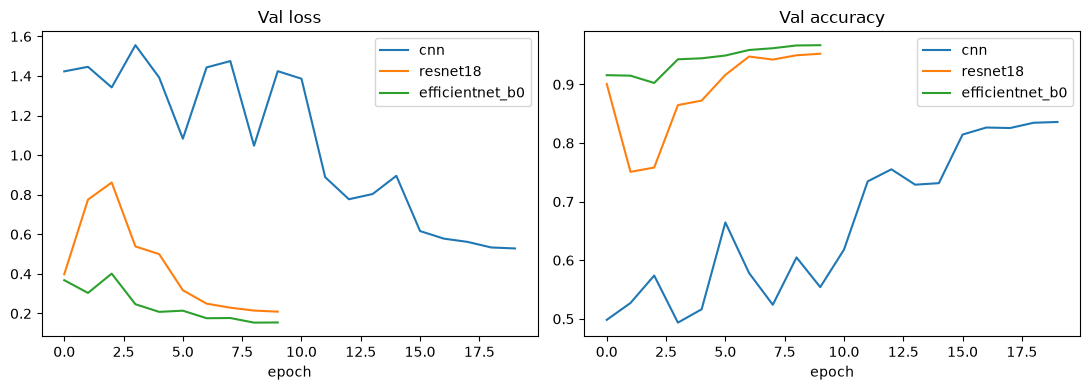

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for r in R:
    ax[0].plot(r["history"]["val_loss"], label=r["model"]); ax[1].plot(r["history"]["val_acc"], label=r["model"])
ax[0].set_title("Val loss"); ax[1].set_title("Val accuracy")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

## Kết luận

| Mô hình | Test accuracy | Macro F1 | Tham số | Epoch | Thời gian train |
|---|---|---|---|---|---|
| CNN tự xây | 83,1% | 0,809 | 1,18M | 20 | khoảng 16,7 phút |
| ResNet18 (pretrained) | 94,0% | 0,923 | 11,18M | 10 | khoảng 7,8 phút |
| EfficientNet-B0 (pretrained) | **96,1%** | **0,953** | 4,02M | 10 | khoảng 8,8 phút |

1. **Transfer learning là yếu tố quyết định.** Hai mô hình pretrained vượt CNN tự xây từ 10,9 đến 13,1 điểm accuracy dù chỉ train 10 epoch, bằng một nửa số epoch của CNN.
2. **EfficientNet-B0 tốt nhất:** cao hơn ResNet18 khoảng 2,2 điểm accuracy và 0,03 macro F1, trong khi chỉ có khoảng 36% số tham số của ResNet18.
3. **Cả ba mô hình đều yếu ở cùng các lớp:** `plastic`, `metal`, `white-glass` (vật liệu trong suốt hoặc phản chiếu) và nhầm lẫn `clothes` với `shoes`, `cardboard` với `paper`. Đây là giới hạn của dữ liệu và độ phân giải 128×128, không chỉ của kiến trúc.
4. **Overfit:** CNN gần như không overfit (nhưng chưa hội tụ hết); ResNet18 và EfficientNet-B0 overfit nhẹ (train cao hơn val khoảng 2,5 đến 3,7 điểm).
5. **Hướng cải thiện:** tăng `IMG_SIZE` lên 224, dùng thêm augmentation, train thêm epoch cho CNN, hoặc thử EfficientNet-B1/B2.

*Lưu ý: kết quả đo một lần chạy với một seed, chênh lệch nhỏ giữa các mô hình có thể thay đổi giữa các lần chạy.*